[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nahuelcosta/generative-networks/blob/main/gan/gan_tutorial.ipynb)

This notebooks is part of the [Generative Networks course](https://www.nahuelcosta.com/teaching/generative-networks).

# Training a GAN on MNIST

Tutorial for training a small GAN to generate MNIST-like handwritten digits.

A GAN has two neural networks trained together:

- The **generator** starts from random noise and tries to produce realistic images.
- The **discriminator** receives an image and tries to decide whether it is real or generated.

The discriminator gives the generator a learning signal, and the generator gradually learns to fool it.

## 0. Dependencies

In [ ]:
# Install the packages used by this notebook.
# In Colab and many course environments these are already installed, so this cell usually just prints a confirmation.
import importlib.util
import subprocess
import sys

packages = {
    "torch": "torch",
    "torchvision": "torchvision",
    "matplotlib": "matplotlib",
    "numpy": "numpy",
}

missing = [
    pip_name
    for import_name, pip_name in packages.items()
    if importlib.util.find_spec(import_name) is None
]

if missing:
    print("Installing missing packages:", ", ".join(missing))
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
else:
    print("All required packages are already installed.")


All required packages are already installed.


## 1. Imports and Reproducibility

In [2]:
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


## 2. Configuration

The defaults below are intentionally modest. You can increase `epochs` to get cleaner samples.

In [3]:
project_root = Path.cwd().parent if Path.cwd().name == "gan" else Path.cwd()
data_dir = project_root / "data"
output_dir = project_root / "gan" / "outputs" / "mnist_gan"
output_dir.mkdir(parents=True, exist_ok=True)

batch_size = 128
z_dim = 64
image_channels = 1
image_size = 28
epochs = 20
learning_rate = 2e-4
beta1 = 0.5
beta2 = 0.999

sample_every_epochs = 5
checkpoint_path = output_dir / "mnist_gan_checkpoint.pt"

## 3. Load MNIST

GAN training is usually easier when image values are centered. We transform MNIST from `[0, 1]` into `[-1, 1]`.

In [4]:
transform = transforms.Compose([
    transforms.ToTensor(), # Convert PIL image to tensor (also scales pixel values to [0, 1])
    transforms.Normalize(mean=(0.5,), std=(0.5,)), # A mean of 0.5 and std of 0.5 scales the pixel values to [-1, 1]
])

train_dataset = datasets.MNIST(
    root=data_dir,
    train=True,
    download=True,
    transform=transform,
)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    drop_last=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
)

len(train_dataset), len(train_loader)

/home/nahuel/.conda/envs/generative-networks/lib/python3.12/site-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 2 worker processes in total. Our suggested max number of worker in current system is 1, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


(60000, 468)

Let's inspect a batch of real MNIST images.

/home/nahuel/.conda/envs/generative-networks/lib/python3.12/site-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 2 worker processes in total. Our suggested max number of worker in current system is 1, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


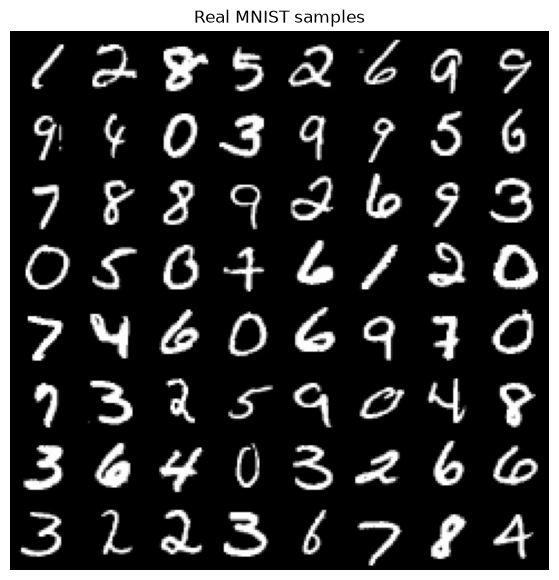

In [5]:
# imshow needs images in the range [0, 1], but our images are normalized to [-1, 1]. We need to denormalize them first.
def denormalize(images):
    return (images + 1) / 2


def show_image_grid(images, title=None, nrow=8):
    images = denormalize(images.detach().cpu()).clamp(0, 1)
    grid = make_grid(images, nrow=nrow, padding=2)
    plt.figure(figsize=(7, 7))
    plt.imshow(grid.permute(1, 2, 0).squeeze(), cmap="gray")
    plt.axis("off")
    if title:
        plt.title(title)
    plt.show()


real_images, real_labels = next(iter(train_loader))
show_image_grid(real_images[:64], title="Real MNIST samples")

## 4. Define the Generator

The generator maps a vector of random noise of shape 64 into a `1 x 28 x 28` image. This version just uses fully connected layers.

The final `Tanh` layer matches our normalized image range of `[-1, 1]`.

In [6]:
class Generator(nn.Module):
    def __init__(self, z_dim=64, image_channels=1, image_size=28):
        super().__init__()
        image_dim = image_channels * image_size * image_size
        self.net = nn.Sequential(
            nn.Linear(z_dim, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(inplace=True),
            nn.Linear(256, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(inplace=True),
            nn.Linear(512, 1024),
            nn.BatchNorm1d(1024),
            nn.ReLU(inplace=True),
            nn.Linear(1024, image_dim),
            nn.Tanh(),
        )
        self.image_channels = image_channels
        self.image_size = image_size

    def forward(self, z):
        images = self.net(z)
        return images.view(z.size(0), self.image_channels, self.image_size, self.image_size)

## 5. Define the Discriminator

The discriminator maps an image to one logit. Positive logits mean "more real", negative logits mean "more fake".

We do **not** add a sigmoid layer here because `BCEWithLogitsLoss` combines sigmoid plus binary cross entropy in a numerically stable way.

In [7]:
class Discriminator(nn.Module):
    def __init__(self, image_channels=1, image_size=28):
        super().__init__()
        image_dim = image_channels * image_size * image_size
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(image_dim, 512),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout(0.3),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout(0.3),
            nn.Linear(256, 1),
        )

    def forward(self, images):
        return self.net(images)

## 6. Initialize Models and Optimizers

The Adam settings below are common for simple GANs. The lower `beta1` helps avoid overly sticky momentum while the two networks chase each other.

In [8]:
def init_weights(module):
    if isinstance(module, nn.Linear):
        nn.init.normal_(module.weight, mean=0.0, std=0.02)
        if module.bias is not None:
            nn.init.zeros_(module.bias)


generator = Generator(z_dim, image_channels, image_size).to(device)
discriminator = Discriminator(image_channels, image_size).to(device)
generator.apply(init_weights)
discriminator.apply(init_weights)

loss = nn.BCEWithLogitsLoss()
g_optimizer = torch.optim.Adam(generator.parameters(), lr=learning_rate, betas=(beta1, beta2))
d_optimizer = torch.optim.Adam(discriminator.parameters(), lr=learning_rate, betas=(beta1, beta2))

fixed_noise = torch.randn(64, z_dim, device=device)

print(generator)
print(discriminator)

Generator(
  (net): Sequential(
    (0): Linear(in_features=64, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Linear(in_features=256, out_features=512, bias=True)
    (4): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): Linear(in_features=512, out_features=1024, bias=True)
    (7): BatchNorm1d(1024, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (8): ReLU(inplace=True)
    (9): Linear(in_features=1024, out_features=784, bias=True)
    (10): Tanh()
  )
)
Discriminator(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=512, bias=True)
    (2): LeakyReLU(negative_slope=0.2, inplace=True)
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=512, out_features=256, bias=True)
    (5): Leaky

## 7. GAN Training Step

Each batch has two phases:

1. **Train the discriminator** on real images labeled `1` and generated images labeled `0`.
2. **Train the generator** so that generated images are classified as real, labeled `1`.

The `detach()` call in the discriminator phase is important: it prevents the discriminator update from changing the generator.

In [9]:
def train_one_epoch(epoch, generator, discriminator, train_loader):
    generator.train()
    discriminator.train()

    d_losses = []
    g_losses = []
    real_scores = []
    fake_scores = []

    for batch_idx, (real_images, _) in enumerate(train_loader):
        real_images = real_images.to(device, non_blocking=True)
        current_batch_size = real_images.size(0)

        real_targets = torch.ones(current_batch_size, 1, device=device)
        fake_targets = torch.zeros(current_batch_size, 1, device=device)

        # 1. Train discriminator.
        d_optimizer.zero_grad(set_to_none=True)

        real_logits = discriminator(real_images)
        d_real_loss = loss(real_logits, real_targets)

        noise = torch.randn(current_batch_size, z_dim, device=device)
        fake_images = generator(noise)
        fake_logits = discriminator(fake_images.detach())
        d_fake_loss = loss(fake_logits, fake_targets)

        d_loss = d_real_loss + d_fake_loss
        d_loss.backward()
        d_optimizer.step()

        # 2. Train generator.
        g_optimizer.zero_grad(set_to_none=True)

        noise = torch.randn(current_batch_size, z_dim, device=device)
        fake_images = generator(noise)
        fake_logits = discriminator(fake_images)
        g_loss = loss(fake_logits, real_targets)

        g_loss.backward()
        g_optimizer.step()

        d_losses.append(d_loss.item())
        g_losses.append(g_loss.item())
        real_scores.append(torch.sigmoid(real_logits).mean().item())
        fake_scores.append(torch.sigmoid(fake_logits).mean().item())

    metrics = {
        "epoch": epoch,
        "d_loss": float(np.mean(d_losses)),
        "g_loss": float(np.mean(g_losses)),
        "real_score": float(np.mean(real_scores)),
        "fake_score": float(np.mean(fake_scores)),
    }
    return metrics

## 8. Sampling and Checkpoint Helpers

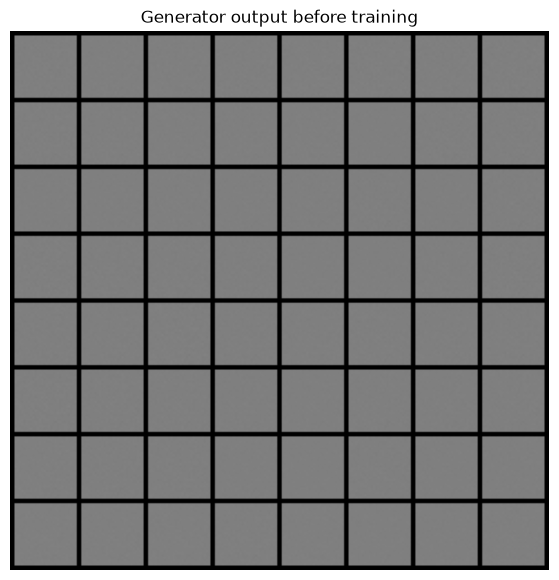

In [10]:
@torch.no_grad()
def sample_images(generator, noise=fixed_noise, title="Generated samples", save_path=None):
    generator.eval()
    images = generator(noise)
    if save_path is not None:
        save_path = Path(save_path)
        save_path.parent.mkdir(parents=True, exist_ok=True)
        grid = make_grid(denormalize(images.cpu()).clamp(0, 1), nrow=8, padding=2)
        plt.imsave(save_path, grid.permute(1, 2, 0).squeeze().numpy(), cmap="gray")
    show_image_grid(images, title=title, nrow=8)


def save_checkpoint(epoch, history):
    torch.save(
        {
            "epoch": epoch,
            "generator_state_dict": generator.state_dict(),
            "discriminator_state_dict": discriminator.state_dict(),
            "g_optimizer_state_dict": g_optimizer.state_dict(),
            "d_optimizer_state_dict": d_optimizer.state_dict(),
            "history": history,
            "config": {
                "z_dim": z_dim,
                "image_channels": image_channels,
                "image_size": image_size,
                "batch_size": batch_size,
                "learning_rate": learning_rate,
            },
        },
        checkpoint_path,
    )


sample_images(generator, title="Generator output before training")

As you can see, the outputs from the generator before training are just noise.

## 9. Train the GAN

Run this cell to train. Early samples will look like static or gray fog. After a few epochs, you should see digit-like shapes emerge.

GAN losses are not as straightforward as classifier losses. A lower generator or discriminator loss is not always better by itself, so inspect generated samples as well as the curves.

Epoch 001/020 | D loss: 1.2754 | G loss: 0.8729 | D(real): 0.588 | D(fake): 0.429
Epoch 002/020 | D loss: 1.2202 | G loss: 1.0958 | D(real): 0.588 | D(fake): 0.359
Epoch 003/020 | D loss: 1.2245 | G loss: 1.0704 | D(real): 0.577 | D(fake): 0.370
Epoch 004/020 | D loss: 1.2483 | G loss: 1.0277 | D(real): 0.567 | D(fake): 0.380
Epoch 005/020 | D loss: 1.2651 | G loss: 0.9555 | D(real): 0.559 | D(fake): 0.405


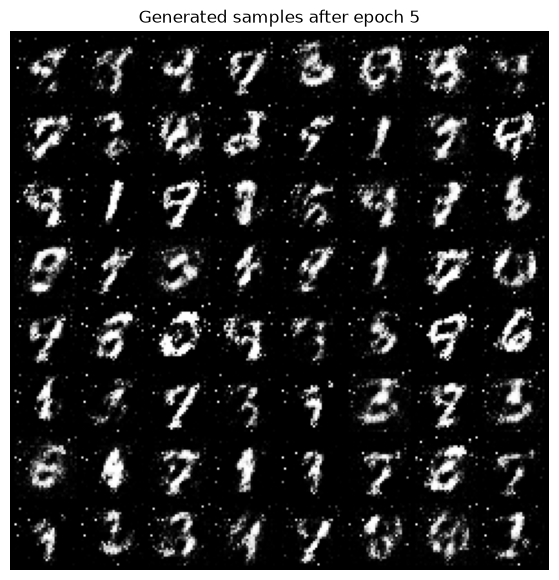

Epoch 006/020 | D loss: 1.2739 | G loss: 0.9349 | D(real): 0.555 | D(fake): 0.412
Epoch 007/020 | D loss: 1.2931 | G loss: 0.8791 | D(real): 0.546 | D(fake): 0.431
Epoch 008/020 | D loss: 1.3020 | G loss: 0.8603 | D(real): 0.542 | D(fake): 0.438
Epoch 009/020 | D loss: 1.3038 | G loss: 0.8514 | D(real): 0.541 | D(fake): 0.441
Epoch 010/020 | D loss: 1.3107 | G loss: 0.8490 | D(real): 0.537 | D(fake): 0.442


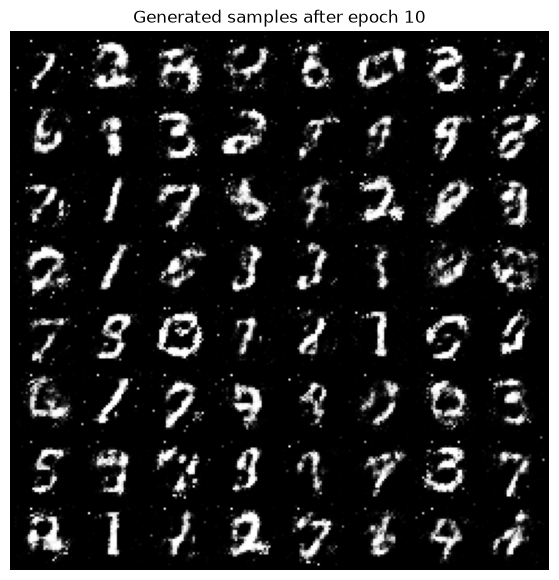

Epoch 011/020 | D loss: 1.3191 | G loss: 0.8254 | D(real): 0.534 | D(fake): 0.451
Epoch 012/020 | D loss: 1.3286 | G loss: 0.8164 | D(real): 0.529 | D(fake): 0.454
Epoch 013/020 | D loss: 1.3365 | G loss: 0.8008 | D(real): 0.525 | D(fake): 0.459
Epoch 014/020 | D loss: 1.3410 | G loss: 0.7939 | D(real): 0.523 | D(fake): 0.461
Epoch 015/020 | D loss: 1.3488 | G loss: 0.7782 | D(real): 0.519 | D(fake): 0.467


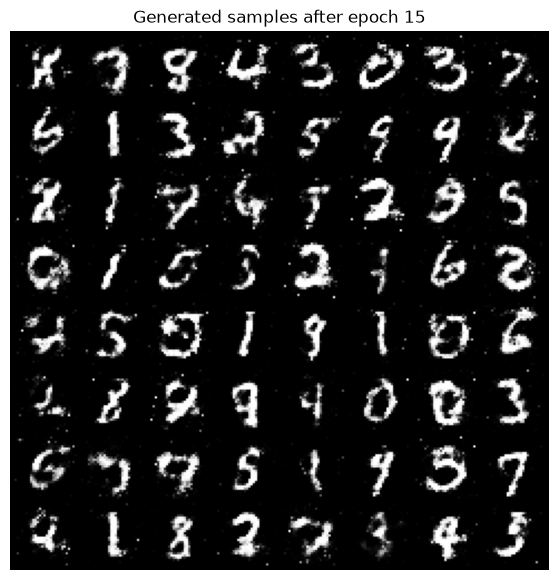

Epoch 016/020 | D loss: 1.3501 | G loss: 0.7749 | D(real): 0.518 | D(fake): 0.468
Epoch 017/020 | D loss: 1.3582 | G loss: 0.7661 | D(real): 0.515 | D(fake): 0.472
Epoch 018/020 | D loss: 1.3586 | G loss: 0.7621 | D(real): 0.514 | D(fake): 0.473
Epoch 019/020 | D loss: 1.3607 | G loss: 0.7569 | D(real): 0.513 | D(fake): 0.475
Epoch 020/020 | D loss: 1.3634 | G loss: 0.7547 | D(real): 0.512 | D(fake): 0.476


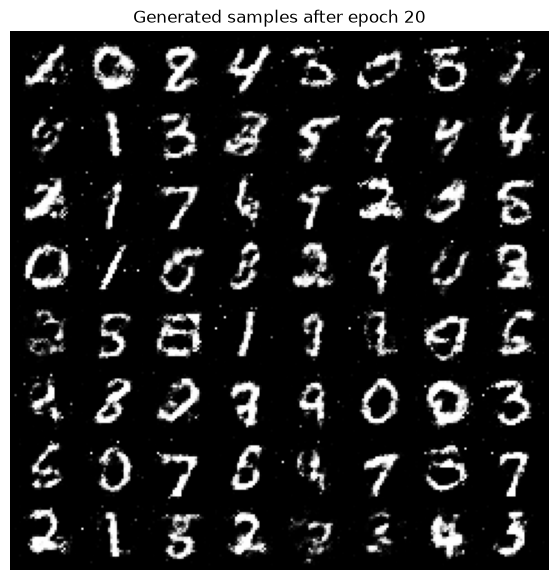

Saved latest checkpoint to: /home/nahuel/generative-networks/gan/outputs/mnist_gan/mnist_gan_checkpoint.pt


In [11]:
history = []

for epoch in range(1, epochs + 1):
    metrics = train_one_epoch(epoch, generator, discriminator, train_loader)
    history.append(metrics)

    print(
        f"Epoch {epoch:03d}/{epochs:03d} | "
        f"D loss: {metrics['d_loss']:.4f} | "
        f"G loss: {metrics['g_loss']:.4f} | "
        f"D(real): {metrics['real_score']:.3f} | "
        f"D(fake): {metrics['fake_score']:.3f}"
    )

    if epoch % sample_every_epochs == 0 or epoch == epochs:
        sample_path = output_dir / f"samples_epoch_{epoch:03d}.png"
        sample_images(generator, title=f"Generated samples after epoch {epoch}", save_path=sample_path)

    save_checkpoint(epoch, history)

print(f"Saved latest checkpoint to: {checkpoint_path}")

## 10. Plot Training Curves

The discriminator and generator are opponents, so curves can oscillate. That is normal. Training is healthier when neither model immediately dominates the other for the entire run.

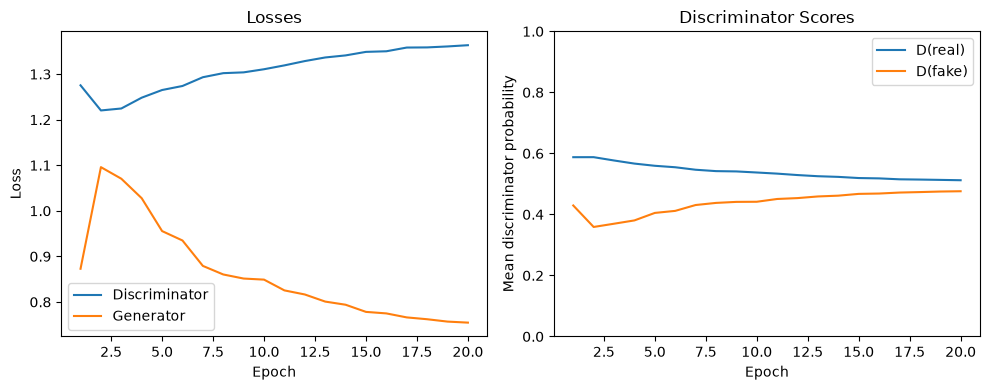

In [16]:
epochs_seen = [row["epoch"] for row in history]

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(epochs_seen, [row["d_loss"] for row in history], label="Discriminator")
plt.plot(epochs_seen, [row["g_loss"] for row in history], label="Generator")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("Losses")

plt.subplot(1, 2, 2)
plt.plot(epochs_seen, [row["real_score"] for row in history], label="D(real)")
plt.plot(epochs_seen, [row["fake_score"] for row in history], label="D(fake)")
plt.xlabel("Epoch")
plt.ylabel("Mean discriminator probability")
plt.ylim(0, 1)
plt.legend()
plt.title("Discriminator Scores")

plt.tight_layout()
plt.show()

## 11. Generate New Digits

After training, sample fresh noise vectors to create new images.

Note this is an unconditional GAN so the generator receives only random noise z and samples sample digits, but you cannot tell it what number to generate.

For a conditional GAN you would need to feed the digit label into both networks.

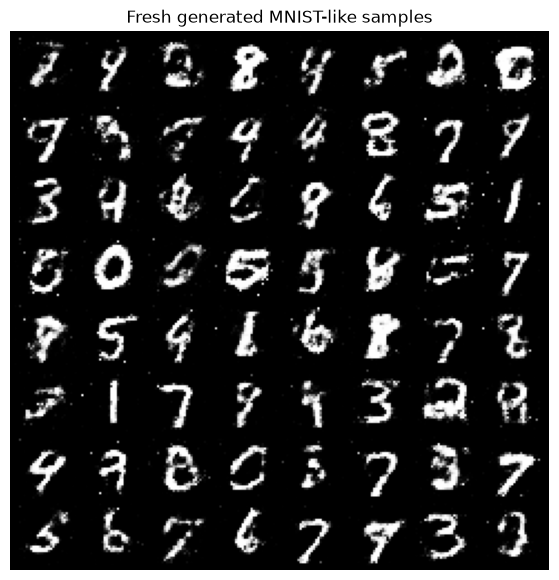

In [17]:
new_noise = torch.randn(64, z_dim, device=device)
sample_images(generator, noise=new_noise, title="Fresh generated MNIST-like samples")

## 12. Latent Space Interpolation

A neat way to inspect a generator is to interpolate between two random noise vectors. If training worked, the generated images should morph smoothly.

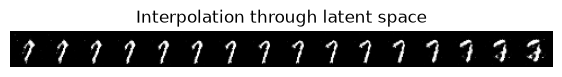

In [18]:
@torch.no_grad()
def interpolate(generator, steps=16):
    generator.eval()
    z_start = torch.randn(1, z_dim, device=device)
    z_end = torch.randn(1, z_dim, device=device)
    weights = torch.linspace(0, 1, steps, device=device).view(steps, 1)
    noise = (1 - weights) * z_start + weights * z_end
    images = generator(noise)
    show_image_grid(images, title="Interpolation through latent space", nrow=steps)


interpolate(generator)

## 13. Loading a Saved Checkpoint

Use this cell later if you restart the kernel and want to resume from the latest saved model.

In [15]:
# checkpoint = torch.load(checkpoint_path, map_location=device)
# generator.load_state_dict(checkpoint["generator_state_dict"])
# discriminator.load_state_dict(checkpoint["discriminator_state_dict"])
# g_optimizer.load_state_dict(checkpoint["g_optimizer_state_dict"])
# d_optimizer.load_state_dict(checkpoint["d_optimizer_state_dict"])
# history = checkpoint["history"]
# print(f"Loaded checkpoint from epoch {checkpoint['epoch']}")

## 14. Things to Try

- Train for more epochs and compare sample quality.
- Increase `z_dim` to 100.
- Replace the fully connected networks with convolutional DCGAN-style networks.
- Add one-sided label smoothing by setting real labels to `0.9` instead of `1.0`.
- Track generated image grids over time to make a training animation.

## Troubleshooting

- If the discriminator loss goes near zero immediately, reduce its size, reduce its learning rate, or add label smoothing.
- If you run out of GPU memory, lower `batch_size`.